Connected to Python 3.15.0

Attività 1 Costruzione del modello:

Il numero medio atteso di conteggi nel punto $x$ è descritto dalla funzione:$$\mu(x) = B + I_0 \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2 \cos^2(\delta x)$$
Disaccoppiamo la funzione nell'inviluppo $E(x)$ e nella parte oscillante $C(x)$:

Inviluppo di diffrazione:
$$E(x) = \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2$$
Frange d'interferenza:
$$C(x) = \cos^2(\delta x)$$

Valori finiti: True
Valori non negativi: True
Simmetria: True
mu(0) = 420.0
B + I0 = 420


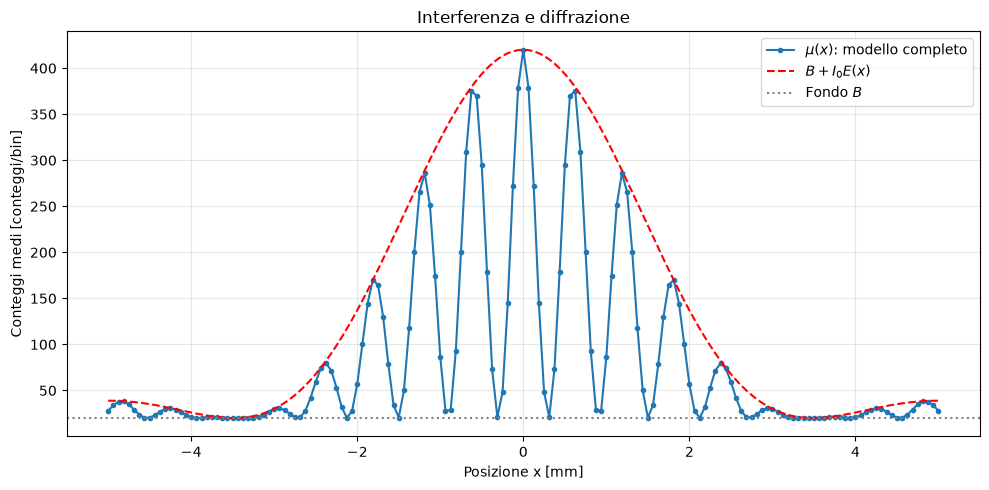

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

B = 20                 
I0 = 400               
alpha = 0.90           
delta = 5.20           

x = np.linspace(-5.0, 5.0, 161)

E = np.sinc(alpha * x / np.pi)**2

C = np.cos(delta * x)**2

mu = B + I0 * E * C

print("Valori finiti:", np.all(np.isfinite(mu)))
print("Valori non negativi:", np.all(mu >= 0))
print("Simmetria:", np.allclose(mu, mu[::-1]))
print("mu(0) =", mu[len(x)//2])
print("B + I0 =", B + I0)

inviluppo_superiore = B + I0 * E

# Grafico
plt.figure(figsize=(10, 5))
plt.plot(x, mu, "o-", markersize=3,
         label=r"$\mu(x)$: modello completo")
plt.plot(x, inviluppo_superiore, "r--",
         label=r"$B+I_0 E(x)$")
plt.axhline(B, color="gray", linestyle=":",
            label=r"Fondo $B$")

plt.xlabel("Posizione x [mm]")
plt.ylabel("Conteggi medi [conteggi/bin]")
plt.title("Interferenza e diffrazione")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

La larghezza del massimo centrale è controllata dal parametro alpha e la distanza tra i frnage dal parametro delta.
x=0 non è una singolarità perchè facendo $$\lim_{x \to 0} \frac{\sin(\alpha x)}{\alpha x} = 1$$


Attività 2: Simulazione di un'Acquisizione Singola

Ciascun bin rappresenta un processo di conteggio indipendente modellato con una distribuzione di Poisson:n_i \sim \text{Poisson}(\mu(x_i))



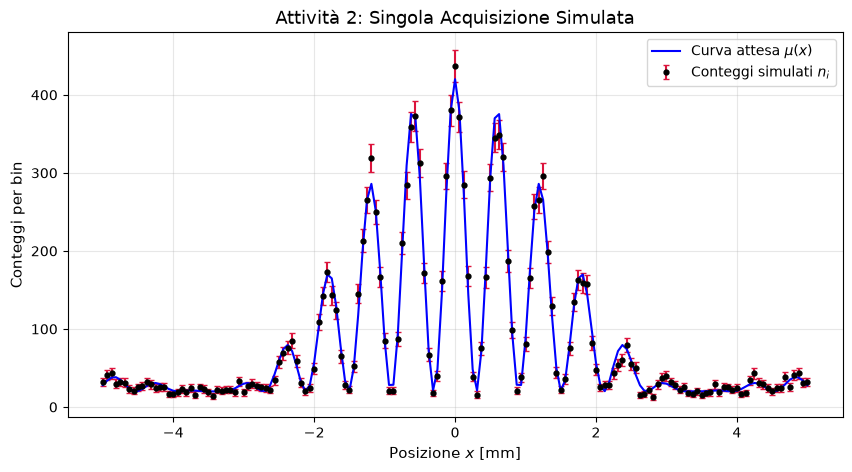

=== CONFRONTO REGIONE CENTRALE ===
Conteggi osservati (N_c): 7603
Valore atteso (mu_c): 7649.41
Scarto (N_c - mu_c): -46.41
Incertezza teorica (sqrt(mu_c)): 87.46
Compatibile con fluttuazione <= 2 sigma? True


In [ ]:

rng = np.random.default_rng(seed=42)

n_i = rng.poisson(mu)

y_err = np.sqrt(n_i)
y_err[y_err == 0] = 1.0

plt.figure(figsize=(10, 5))
plt.errorbar(
    x,
    n_i,
    yerr=y_err,
    fmt='o',
    markersize=3.5,
    color='black',
    ecolor='crimson',
    capsize=2,
    label='Conteggi simulati $n_i$',
)
plt.plot(x, mu, label=r'Curva attesa $\mu(x)$', color='blue', linewidth=1.5)

plt.title('Attività 2: Singola Acquisizione Simulata', fontsize=13)
plt.xlabel('Posizione $x$ [mm]', fontsize=11)
plt.ylabel('Conteggi per bin', fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
 
mask_c = np.abs(x) < 1.2
N_c = np.sum(n_i[mask_c])  
mu_c = np.sum(mu[mask_c])  

diff_c = N_c - mu_c
sigma_c = np.sqrt(mu_c)

print('=== CONFRONTO REGIONE CENTRALE ===')
print(f'Conteggi osservati (N_c): {N_c}')
print(f'Valore atteso (mu_c): {mu_c:.2f}')
print(f'Scarto (N_c - mu_c): {diff_c:.2f}')
print(f'Incertezza teorica (sqrt(mu_c)): {sigma_c:.2f}')
print(
    f'Compatibile con fluttuazione <= 2 sigma? {abs(diff_c) <= 2 * sigma_c}'
)

Dalle stime ottenute nella regione centrale ($\vert{}x_i\vert{} < 1.2\text{ mm}$), calcoliamo la differenza tra i conteggi osservati $N_c$ e il valore atteso teorico $\mu_c$:

$\Delta N = N_c - \mu_c$

L'incertezza standard associata a tale misura è data dalla deviazione standard della distribuzione di Poisson, pari a $\sigma_{N_c} = \sqrt{\mu_c}$.   Verifichiamo se lo scarto rientra nell'intervallo di compatibilità statistica controllando se la differenza normalizzata è inferiore a 2 (ovvero $\lvert N_c - \mu_c \rvert \le 2\sqrt{\mu_c}$)

La differenza osservata risulta del tutto compatibile con una normale fluttuazione statistica intrinseca del processo di misura Poissoniano. Trattandosi di un esperimento stocastico, scarti di questa entità rientrano pienamente nella variabilità attesa del sistema.

Attività 3: Distribuzione dello Stimatore ($M = 2000$)

Eseguiamo $M = 2000$ pseudo-esperimenti salvando i risultati in una matrice di dimensione $M \times 161$ per valutare lo stimatore $N_c^{(j)}$.

=== DISTRIBUZIONE DELLO STIMATORE N_c ===
Media simulata: 7649.77
Valore atteso mu_c: 7649.41
Deviazione standard (dof=1): 88.37
Deviazione standard teorica: 87.46
Errore sulla media simulata: 1.9761
Scarto relativo: 0.00469%


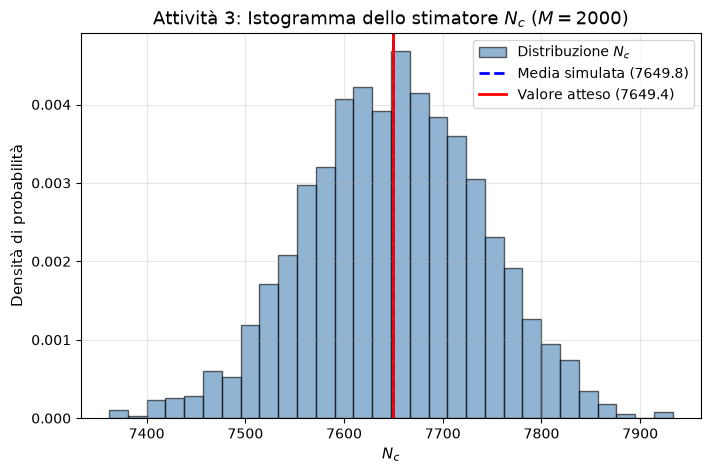

In [ ]:
M = 2000  


sim_matrix = rng.poisson(lam=mu, size=(M, len(x)))


N_c_vec = np.sum(sim_matrix[:, mask_c], axis=1)

# Statistiche campionarie
mean_Nc = np.mean(N_c_vec)
std_Nc = np.std(N_c_vec, ddof=1)  
err_mean = std_Nc / np.sqrt(M)
rel_bias = abs(mean_Nc - mu_c) / mu_c
sigma_theory_Nc = np.sqrt(mu_c)

print("=== DISTRIBUZIONE DELLO STIMATORE N_c ===")
print(f"Media simulata: {mean_Nc:.2f}")
print(f"Valore atteso mu_c: {mu_c:.2f}")
print(f"Deviazione standard (dof=1): {std_Nc:.2f}")
print(f"Deviazione standard teorica: {sigma_theory_Nc:.2f}")
print(f"Errore sulla media simulata: {err_mean:.4f}")
print(f"Scarto relativo: {rel_bias:.5%}")


plt.figure(figsize=(8, 5))
plt.hist(
    N_c_vec,
    bins=30,
    density=True,
    alpha=0.6,
    color="steelblue",
    edgecolor="black",
    label="Distribuzione $N_c$",
)
plt.axvline(
    mean_Nc, color="blue", linestyle="--", lw=2, label=f"Media simulata ({mean_Nc:.1f})"
)
plt.axvline(
    mu_c, color="red", linestyle="-", lw=2, label=f"Valore atteso ({mu_c:.1f})"
)

plt.title(r"Attività 3: Istogramma dello stimatore $N_c$ ($M = 2000$)", fontsize=13)
plt.xlabel("$N_c$", fontsize=11)
plt.ylabel("Densità di probabilità", fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

L'incertezza associata a una singola acquisizione del conteggio totale regionale $N_c$ è descritta dalla deviazione standard teorica della distribuzione di Poisson, pari a $\sigma_{N_c} = \sqrt{\mu_c}$. Rappresenta l'ampiezza delle fluttuazioni statistiche intrinseche che ci si attende ripetendo una singola misura.

 Aumentando il numero di pseudo-esperimenti $M$ riduce l'errore standard della media simulata (che scala come $\text{sem} = \frac{\sigma}{\sqrt{M}}$). Questo permette di stimare con maggiore precisione la media e la deviazione standard della distribuzione dello stimatore, riducendo la varianza campionaria e verificando con accuratezza la convergenza al comportamento gaussiano previsto dal Teorema del Limite Centrale.

 La sottrazione di un fondo noto rimuove unicamente il valore medio sistematico associato al fondo, correggendo il bias della misura. Tuttavia, non elimina le fluttuazioni stocastiche intrinseche generate dagli eventi di fondo stessi; anzi, per la propagazione degli errori, la sottrazione di una stima del fondo incrementa la varianza complessiva del segnale netto ($\sigma_{\text{netto}}^2 = \sigma_{\text{segnale}}^2 + \sigma_{\text{fondo}}^2$).

Attività 4: Dipendenza dalla Statistica

Studio della variazione dell'incertezza relativa $r(s) = \frac{\sigma_{N_c}(s)}{E[N_c(s)]}$ al variare del fattore di scala dell'esposizione $s \in \{0.25, 0.5, 1, 2, 4, 8\}$ per verificare la legge $r(s) \propto 1/\sqrt{s}$.

=== TABELLA DIPENDENZA DALLA STATISTICA ===
s		Media		Std		r(s)		r(s)*sqrt(s)
-----------------------------------------------------------------
0.25    1911.43         44.32       0.02319     0.01159     
0.50    3823.32         62.25       0.01628     0.01151     
1.00    7648.11         89.24       0.01167     0.01167     
2.00    15302.61        119.74      0.00783     0.01107     
4.00    30601.07        175.69      0.00574     0.01148     
8.00    61197.99        252.17      0.00412     0.01165     


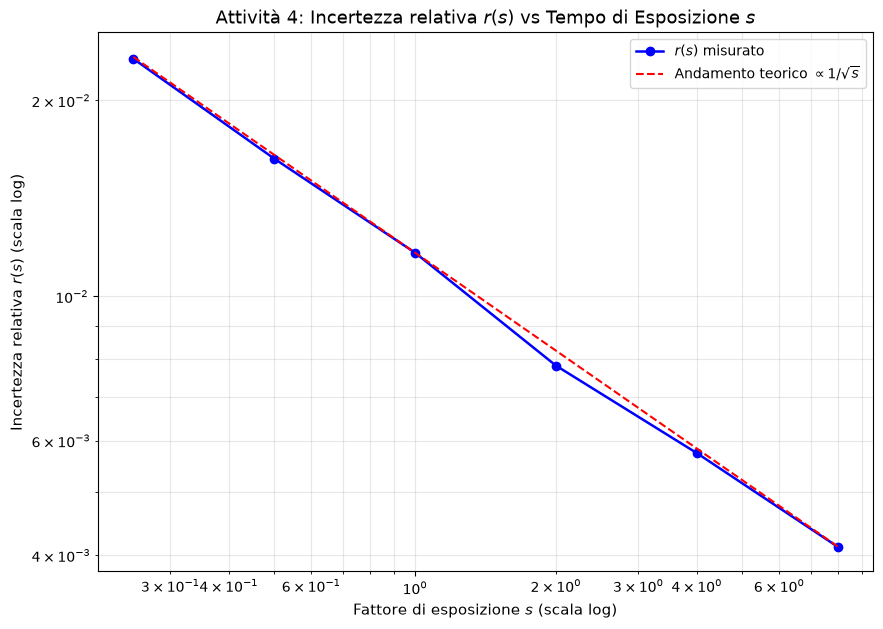

In [20]:
s_vec = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
M_s = 1000

r_s_list = []
invariant_list = []
E_Nc_list = []
sigma_Nc_list = []

print("=== TABELLA DIPENDENZA DALLA STATISTICA ===")
print("s\t\tMedia\t\tStd\t\tr(s)\t\tr(s)*sqrt(s)")
print("-" * 65)

for s in s_vec:
    mu_s = s * mu
    matrice_s = rng.poisson(lam=mu_s, size=(M_s, len(x)))
    Nc_s = np.sum(matrice_s[:, mask_c], axis=1)

    mean_s = np.mean(Nc_s)
    std_s = np.std(Nc_s, ddof=1)

    r_s = std_s / mean_s
    prod = r_s * np.sqrt(s)

    r_s_list.append(r_s)
    invariant_list.append(prod)

    print(f"{s:<8.2f}{mean_s:<16.2f}{std_s:<12.2f}{r_s:<12.5f}{prod:<12.5f}")

plt.figure(figsize=(10, 7))
plt.loglog(s_vec, r_s_list, "ob-", lw=1.8, label=r"$r(s)$ misurato")


ref_trend = r_s_list[2] * np.sqrt(1.0 / np.array(s_vec))
plt.loglog(
    s_vec, ref_trend, "--r", label=r"Andamento teorico $\propto 1/\sqrt{s}$"
)

plt.title(
    r"Attività 4: Incertezza relativa $r(s)$ vs Tempo di Esposizione $s$",
    fontsize=13,
)
plt.xlabel("Fattore di esposizione $s$ (scala log)", fontsize=11)
plt.ylabel(r"Incertezza relativa $r(s)$ (scala log)", fontsize=11)
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

Per dimezzare l'incertezza relativa ($r(s) \to \frac{r(s)}{2}$), il tempo di acquisizione (o il fattore $s$) deve aumentare di un fattore 4